# Red de comunicación y comunidades: exploración

Consulta la [metodología](../docs/metodologia.md) y ejecuta las etapas en orden. Los comentarios se calculan con los resultados guardados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("email_community_analysis")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from email_community_analysis.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Red de comunicación y comunidades: eda

La proyección tiene **20 componentes**, con **986 nodos** en la mayor y **19 aislados**. PageRank describe posición estructural en la red dirigida; no demuestra influencia causal, productividad ni calidad de trabajo.


,Indicador,Valor
0,aristas_no_dirigidas,16064.000000
1,componentes,20.000000
2,componente_mayor,986.000000
3,aislados,19.000000
4,densidad,0.031841
5,reciprocidad_dirigida,0.711220


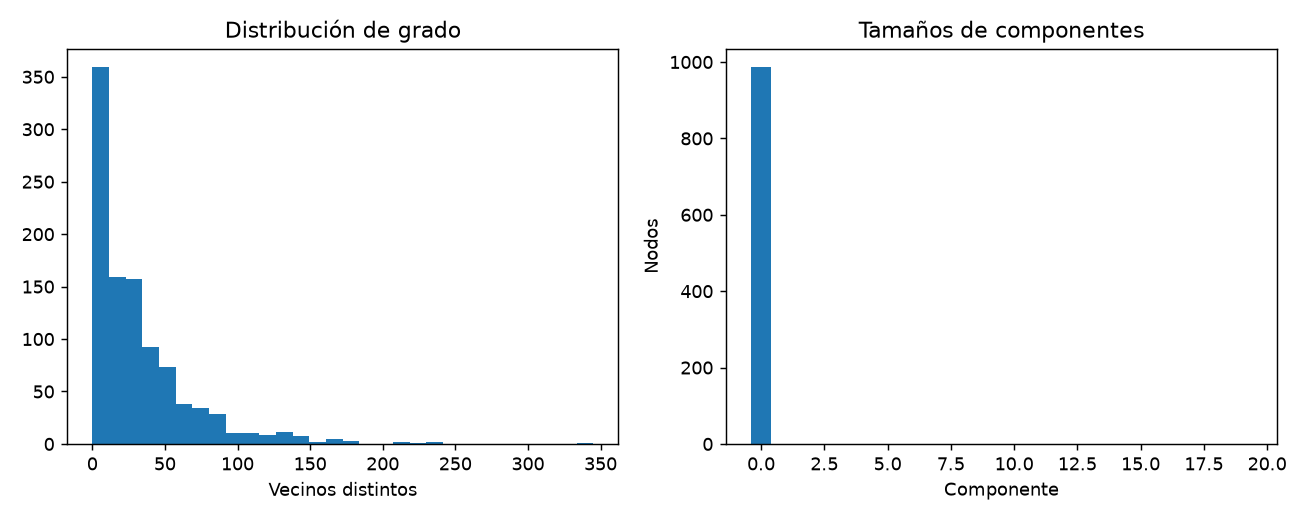

,node,degree,in_degree,out_degree,pagerank
0,160,345,211,333,0.007495
1,62,214,178,189,0.005897
2,86,216,153,201,0.005711
3,107,219,168,203,0.005568
4,121,232,156,221,0.005232
5,5,169,123,155,0.005122
6,129,162,138,135,0.004950
7,183,171,142,158,0.004727
8,64,168,135,112,0.004677
9,434,183,150,156,0.004654


In [2]:
from email_community_analysis.analysis import run_stage
import pandas as pd
metrics,comment=run_stage(PROJECT_ROOT,"eda")
display(Markdown(comment))
scalars={k:v for k,v in metrics.items() if not isinstance(v,(dict,list))}
if scalars:display(pd.DataFrame(list(scalars.items()),columns=["Indicador","Valor"]))
if "candidatos" in metrics:display(pd.DataFrame(metrics["candidatos"]))
for filename in ["eda.png","evaluacion.png"]:
    path=PROJECT_ROOT/"reports/eda"/filename
    if path.exists():display(Image(filename=str(path)))
for filename in ["estimaciones.csv","metricas_test.csv","horas_por_empleado.csv", "estabilidad_semillas.csv", "centralidad.csv"]:
    path=PROJECT_ROOT/"reports/eda"/filename
    if path.exists():display(pd.read_csv(path).head(20))

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/02_analisis_exploratorio.json")
from email_community_analysis.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))

[Abrir informe integral](../reports/informe_final/informe_final.md)